# Optimal CDR curves and apprate-optimized ensemble

Global ERW CDR over time and cumulative CDR efficiency (applied to GCAM control and rescaled, lower deployment ceiling).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.colors import to_rgba

# --- run identity ---
EXP_SET_MAIN = "exe_central1p5"
idx          = "001"
SAVE_GROUP   = "gcam"
EXP_SET      = "exe_central1p5"
EXP_GROUPS   = [   # one per cec_factor, merged along cec_factor
    "gcam_opr_full2_cec0p1", "gcam_opr_full2_cec1", "gcam_opr_full2_cec2",
    "gcam_opr_full2_cec3", "gcam_opr_full2_cec4",
]

CDR_METRIC       = "cdr_adv_region"   # time-integrated, ranks combos
CDR_METRIC_GLOBE = (CDR_METRIC.replace("_region", "_globe")
                    if CDR_METRIC.endswith("_region") else f"{CDR_METRIC}_globe")
CROPFRAC_MAX     = 1.0                # cropfrac_ERW ceiling for land-limited selections

# only these are loaded (keeps the S3 read short); add a variable to use it downstream
LOAD_VARS = [
    CDR_METRIC, "gcam_cdr", "cropfrac_ERW",
    "catbudget_adv_region", "catbudget_tflx_region", "catbudget_sic_region",
    "total_dissolution_region",
]

ds_bygroup = []
for exp_group in EXP_GROUPS:
    datpath = (
        f"s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/{SAVE_GROUP}/"
        f"{exp_group}/{EXP_SET_MAIN}_{idx}_multiSchedule/{EXP_SET}"
    )
    ds_bygroup.append(xr.open_zarr(os.path.join(datpath, "ds_cdr_globalScaling_constApp_SUM.zarr"))[LOAD_VARS])
dssum = xr.combine_by_coords(ds_bygroup, combine_attrs="override").load()

print(f"EXP_SET:       {EXP_SET}")
print(f"cec_factor:    {dssum.cec_factor.values}")
print(f"apprate_base:  {dssum.apprate_base.values}")
print(f"dustrad:       {dssum.dustrad.values}")
print(f"sites:         {dssum.sizes['site']}")
print(f"loaded:        {sum(v.nbytes for v in dssum.data_vars.values()) / 1e6:.0f} MB")

EXP_SET:       exe_central1p5
cec_factor:    [0.1 1.  2.  3.  4. ]
apprate_base:  [ 0.1   0.25  0.5   1.    2.5   5.   10.   20.   30.  ]
dustrad:       [ 0.2  0.5  1.   2.5  5.  10.  20.  30. ]
sites:         32
loaded:        52 MB


In [2]:
SAVE_ON  = True
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/fx-bestCdrCurves"
(savehere / "panels").mkdir(parents=True, exist_ok=True)

## 1. Per-region optima

Each selection maximizes time-integrated `CDR_METRIC` per region, keeping `cec_factor` as a dimension.

| name | optimized over | land limit |
|---|---|---|
| `best_lim` | `apprate_base` + `dustrad` | yes |
| `best_nolim` | `apprate_base` + `dustrad` | no |
| `ens_lim` | `apprate_base`, at every (`cec_factor`, `dustrad`) | yes |
| `ens_nolim` | `apprate_base`, at every (`cec_factor`, `dustrad`) | no |

The land limit imposes `cropfrac_ERW <= CROPFRAC_MAX` at every time step. If no combo fits, the least-infeasible one is used and flagged in `feasible`.

In [3]:
ENSEMBLE_MIN_CEC = 1.0   # ensembles use cec_factor >= this; the "best" cases keep every cec_factor


def _regional(ds):
    """Drop vars without a 'site' dim."""
    return ds.drop_vars([v for v in ds.data_vars if "site" not in ds[v].dims])


def _pick(ds, metric, dims):
    """Joint argmax of `metric` over `dims`, returning the winning slice of `ds`."""
    stacked  = metric.stack(combo=tuple(dims))
    best_pos = stacked.fillna(-np.inf).argmax("combo").compute()
    return ds.sel({d: stacked[d].isel(combo=best_pos).reset_coords(drop=True) for d in dims})


def _optimize(ds, dims, land_limit):
    """Maximize time-integrated CDR over `dims`, separately for every remaining coordinate."""
    cdr_integrated = ds[CDR_METRIC].sum("time").compute()

    if land_limit:
        max_cropfrac  = ds["cropfrac_ERW"].max("time").compute()
        feasible      = max_cropfrac <= CROPFRAC_MAX
        none_feasible = ~feasible.any(dim=dims)
        # rank feasible combos by CDR; if none is feasible, take the least exceedance
        metric = xr.where(none_feasible, -max_cropfrac, cdr_integrated.where(feasible))
    else:
        metric = cdr_integrated

    out = _pick(ds, metric, dims).compute()
    out["feasible"] = (~none_feasible if land_limit
                       else out["cropfrac_ERW"].max("time") <= CROPFRAC_MAX)
    out[CDR_METRIC_GLOBE] = out[CDR_METRIC].sum("site")
    return out


def build_selections(ds):
    """The four optima, keyed by name."""
    dsr     = _regional(ds)
    dsr_ens = dsr.isel(cec_factor=(dsr.cec_factor >= ENSEMBLE_MIN_CEC).values)
    return {
        "best_lim":   _optimize(dsr,     ("apprate_base", "dustrad"), land_limit=True),
        "best_nolim": _optimize(dsr,     ("apprate_base", "dustrad"), land_limit=False),
        "ens_lim":    _optimize(dsr_ens, ("apprate_base",),           land_limit=True),
        "ens_nolim":  _optimize(dsr_ens, ("apprate_base",),           land_limit=False),
    }


sel_control = build_selections(dssum)

for name, ds_sel in sel_control.items():
    print(f"{name:>11}  dims {dict(ds_sel.sizes)}  land-infeasible entries: "
          f"{int((~ds_sel['feasible']).sum())}")

   best_lim  dims {'site': 32, 'cec_factor': 5, 'time': 80}  land-infeasible entries: 0
 best_nolim  dims {'site': 32, 'cec_factor': 5, 'time': 80}  land-infeasible entries: 89
    ens_lim  dims {'site': 32, 'dustrad': 8, 'cec_factor': 4, 'time': 80}  land-infeasible entries: 0
  ens_nolim  dims {'site': 32, 'dustrad': 8, 'cec_factor': 4, 'time': 80}  land-infeasible entries: 307


## 2. Rescaled control

The control rescaled so peak annual global CDR is `L_TARGET_GT`, then re-selected. All variables follow this scaling linearly.

In [4]:
L_TARGET_GT = 0.5          # peak annual global CDR (Gt CO2/yr) for the rescaled row
SCALED_VARS = LOAD_VARS    # all mass-extensive, so they scale linearly

gcam_peak_t  = float(dssum["gcam_cdr"].sum("site").max())
scale_factor = (L_TARGET_GT * 1e9) / gcam_peak_t

dssum_scaled = dssum.copy()
for _var in SCALED_VARS:
    if _var in dssum_scaled:
        dssum_scaled[_var] = dssum_scaled[_var] * scale_factor

sel_scaled = build_selections(dssum_scaled)

print(f"GCAM peak {gcam_peak_t / 1e9:.3f} Gt CO2/yr -> {L_TARGET_GT:g} "
      f"(scale factor {scale_factor:.4f})")
print(f"land-infeasible entries, rescaled best_lim: "
      f"{int((~sel_scaled['best_lim']['feasible']).sum())}")

GCAM peak 4.631 Gt CO2/yr -> 0.5 (scale factor 0.1080)
land-infeasible entries, rescaled best_lim: 0


## 3. Figure

- **Timeseries:** the three cases and the GCAM target. Gray ribbon: min/max of both ensembles over members clearing `MIN_CDR_EFFICIENCY`. Hatching: land-limited shortfall.
- **Bars:** cumulative advected CDR / tflx / SIC as a fraction of the cumulative GCAM target, in each curve's color (solid = CDR). Cap: dissolution potential. Gray: rock that never dissolved.
- **Markers** tie each curve's end to the top of its bar's advected-CDR segment.

In [5]:
# ============================================================
# USER OPTIONS -- data selection
# ============================================================
CEC_FACTOR_TO_PLOT  = 1.0         # cec_factor for all three cases
LOWER_SA_DUSTRAD    = 10.0        # dustrad for "Lower surface area"
LOWER_SA_ENSEMBLE   = "ens_lim"   # "ens_lim" or "ens_nolim"
MIN_CDR_EFFICIENCY  = 0.10        # ribbon drops ensemble members below this cumulative efficiency
RIBBON_INCLUDE_BEST = True        # fold the "best" curves into the ribbon so they never poke outside

CDR_UNITS   = "GtCO2"
_UNIT_SCALE = {"t": 1.0, "MtCO2": 1e-6, "GtCO2": 1e-9}
_UNIT_LABEL = {"t": "t CO$_2$", "MtCO2": "Mt CO$_2$", "GtCO2": "Gt CO$_2$"}
START_YEAR  = 2020

# ============================================================
# USER OPTIONS -- cases
# ============================================================
CASE_KEYS = ["best_nolim", "best_lim", "lowerSA"]   # timeseries z-order

CASE_LABELS = {
    "best_lim":   "Best (land limit)",
    "best_nolim": "Best (no land limit)",
    "lowerSA":    "Lower surface area",
}
CASE_LABELS_WRAPPED = {}   # optional bar-tick line breaks

CASE_PALETTE  = "original"   # "original" | "carbonplan" | "carbonplan_triad"
CASE_PALETTES = {
    "original":         {"best_lim": "#0072B2", "best_nolim": "#009E73", "lowerSA": "#D55E00"},   # Okabe-Ito
    "carbonplan":       {"best_lim": "#85a2f7", "best_nolim": "#7eb36a", "lowerSA": "#ea9755"},   # CP blue / green / orange
    "carbonplan_triad": {"best_lim": "#64b9c4", "best_nolim": "#d4c05e", "lowerSA": "#f07071"},   # CP teal / yellow / red
}
CASE_COLOR     = CASE_PALETTES[CASE_PALETTE]
CASE_LINEWIDTH = {"best_lim": 6, "best_nolim": 3.0, "lowerSA": 3.0}
TARGET_LABEL   = "GCAM target"

# ============================================================
# USER OPTIONS -- figure
# ============================================================
FIGSIZE, DPI   = (9, 6.3), 300
TOP_YLIM       = (-0.01, 5)      # None -> autoscale, floor at 0
BOTTOM_YLIM    = (-0.01, 0.55)
XLIM           = (2020, 2099)
XLIM_LABEL_PAD = 14              # extra years for end-of-line labels

FONTSIZE_LABEL, FONTSIZE_TICK = 20, 16

TARGET_COLOR, TARGET_LINEWIDTH = "#333333", 6
RIBBON_COLOR, RIBBON_ALPHA     = "#999999", 0.18
NOLAND_HATCH_COLOR   = "#bbbbbb"   # land-limited shortfall
NOLAND_HATCH_PATTERN = "/"
NOLAND_HATCH_ALPHA   = 0.6
plt.rcParams["hatch.linewidth"] = 0.9

# curve-end + bar markers; in_layout=False keeps the overhanging end markers from shrinking the panel
SHOW_EXPORT_MARKERS = True
MARKER_KW = dict(marker="o", ls="none", ms=11, mec="white", mew=1.4, zorder=12, clip_on=False,
                 in_layout=False)

ADD_LINE_LABELS = False   # end-of-line labels
LABEL_MIN_GAP   = 0.22
LABEL_FONTSIZE  = 12

ROW_HSPACE             = 0.08
PANEL_WSPACE           = 0.05
BAR_PANEL_WIDTH        = 4
XAXIS_BOTTOM_ONLY      = True
BAR_XTICKS_BOTTOM_ONLY = True

SHOW_ROW_TITLES    = False
ROW_TITLE_FONTSIZE = 17
ROW_TITLES = {
    "control": "GCAM central 1.5$\\degree$C control",
    "scaled":  f"Rescaled to {L_TARGET_GT:g} Gt CO$_2$ yr$^{{-1}}$ peak",
}

# ============================================================
# USER OPTIONS -- bar panel
# ============================================================
SHOW_DISS_POT_CAP  = True
BAR_YLIM           = (0, 1)
BAR_WIDTH          = 0.1
BAR_GROUP_GAP      = 0.2
BAR_XTICK_ROTATION = 32
BAR_YLABEL_PAD     = 12

UNWEATHERED_FILL_COLOR, UNWEATHERED_FILL_ALPHA = "#e5e4e4", 0.9   # undissolved remainder
STACK_ALPHA = {"adv": 1.0, "tflx": 0.5, "sic": 0.2}
STACK_EDGE_COLOR, STACK_EDGE_LW = "white", 1.2   # gaps between stack segments

CAP_COLOR, CAP_LINEWIDTH = "#222222", 2.2
BAR_FONTSIZE_LABEL, BAR_FONTSIZE_TICK = FONTSIZE_LABEL, FONTSIZE_TICK

 control | ribbon members passing efficiency threshold: 33 / 64
  scaled | ribbon members passing efficiency threshold: 36 / 64


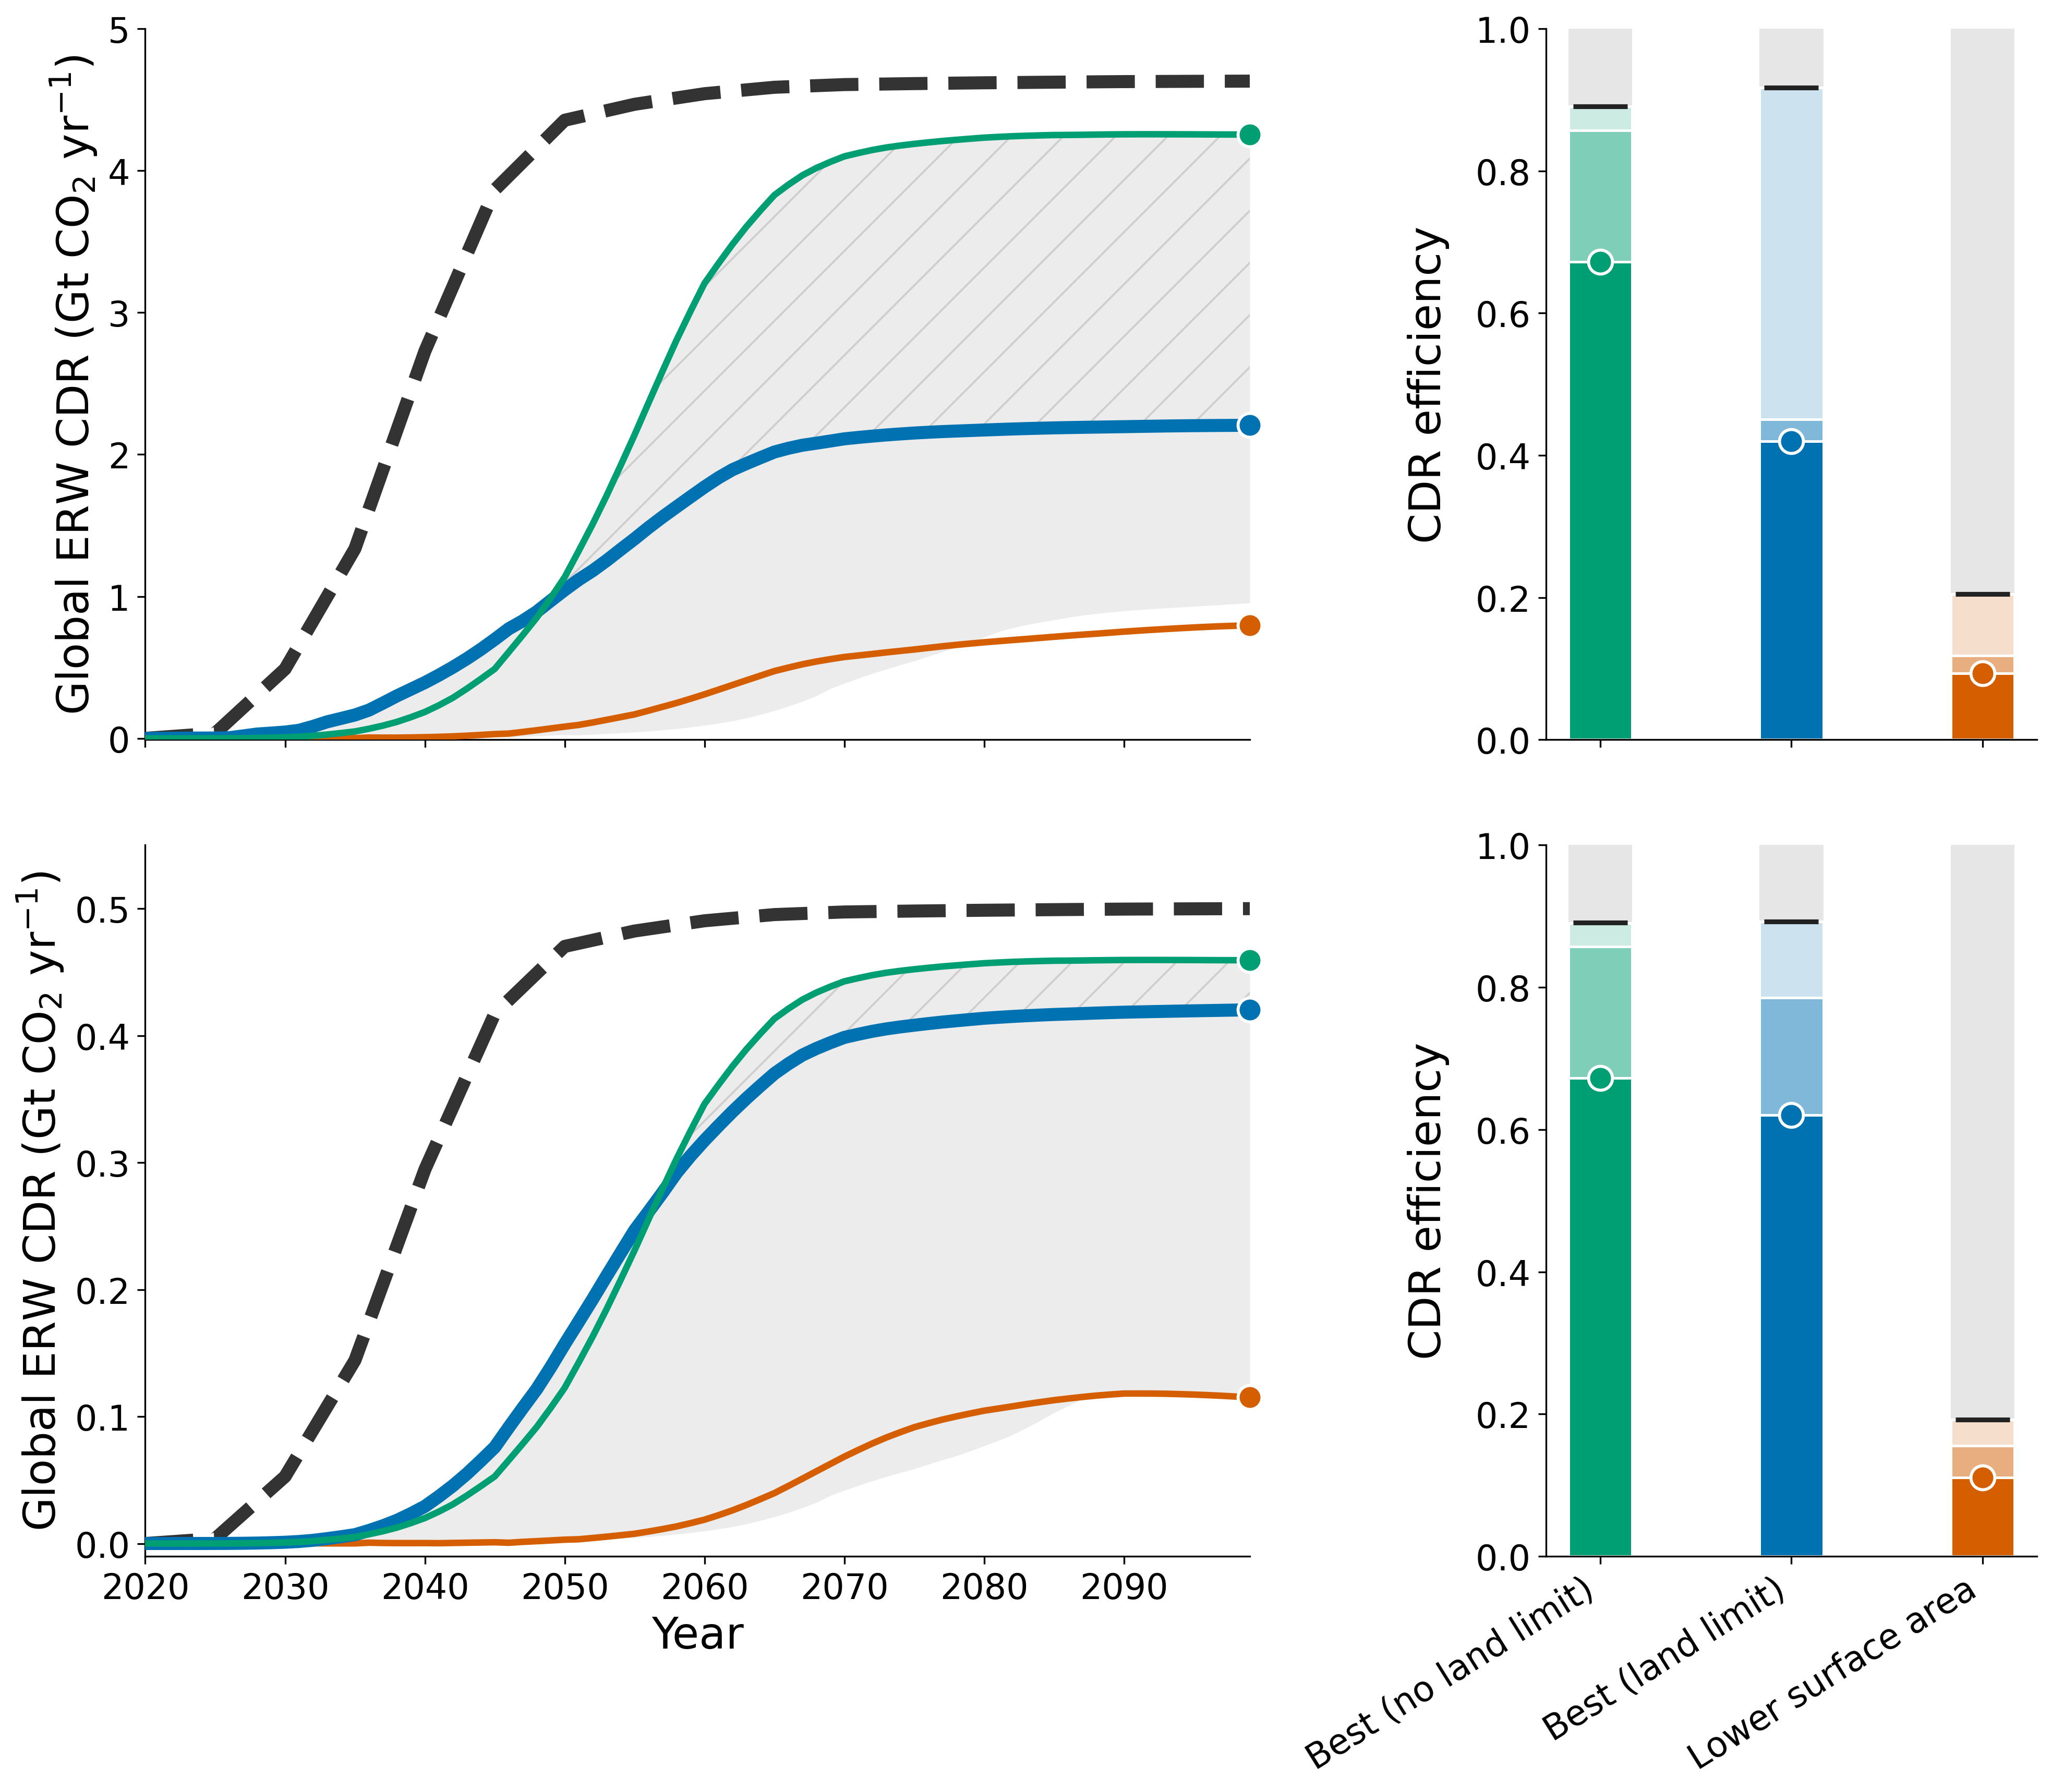

 control | Best (no land limit)   adv 0.672  tflx 0.185  sic 0.034  diss_pot 0.891
 control | Best (land limit)      adv 0.420  tflx 0.031  sic 0.466  diss_pot 0.917
 control | Lower surface area     adv 0.094  tflx 0.024  sic 0.087  diss_pot 0.205
  scaled | Best (no land limit)   adv 0.672  tflx 0.185  sic 0.034  diss_pot 0.891
  scaled | Best (land limit)      adv 0.621  tflx 0.165  sic 0.107  diss_pot 0.893
  scaled | Lower surface area     adv 0.111  tflx 0.045  sic 0.037  diss_pot 0.192


In [6]:
def _row_cases(sel):
    """The three plotted cases from one build_selections() result."""
    return {
        "best_lim":   sel["best_lim"].sel(cec_factor=CEC_FACTOR_TO_PLOT),
        "best_nolim": sel["best_nolim"].sel(cec_factor=CEC_FACTOR_TO_PLOT),
        "lowerSA":    sel[LOWER_SA_ENSEMBLE].sel(cec_factor=CEC_FACTOR_TO_PLOT,
                                                 dustrad=LOWER_SA_DUSTRAD),
    }


def _ribbon(sel, cases, min_efficiency=True):
    """Pointwise min/max of both ensembles' global CDR over members clearing MIN_CDR_EFFICIENCY.
    Returns (min, max, n_kept, n_total)."""
    eff_floor = MIN_CDR_EFFICIENCY if min_efficiency else -np.inf
    lo, hi, n_ok, n_tot = [], [], 0, 0
    for key in ("ens_lim", "ens_nolim"):
        ens = sel[key]
        cdr = ens[CDR_METRIC_GLOBE]                                      # (cec_factor, dustrad, time)
        ok  = (cdr.sum("time") / ens["gcam_cdr"].sum(("site", "time"))) >= eff_floor
        n_ok, n_tot = n_ok + int(ok.sum()), n_tot + ok.size
        masked = cdr.where(ok)
        lo.append(masked.min(("cec_factor", "dustrad")))
        hi.append(masked.max(("cec_factor", "dustrad")))

    # fmin/fmax ignore NaN, so an ensemble with no eligible members drops out
    r_min = np.fmin(*lo)
    r_max = np.fmax(*hi)
    if RIBBON_INCLUDE_BEST:
        for key in ("best_lim", "best_nolim"):
            best = cases[key][CDR_METRIC_GLOBE].reset_coords(drop=True)
            r_min, r_max = np.fmin(r_min, best), np.fmax(r_max, best)
    return r_min, r_max, n_ok, n_tot


def _cumulative_budget(ds_slice, gcam_target_cum):
    """Cumulative cation-budget terms / cumulative GCAM target. Sinks are stored negative;
    sic is clipped at 0 where it is a cation source."""
    adv  = -ds_slice["catbudget_adv_region"].sum(("site", "time")).compute()
    tflx = -ds_slice["catbudget_tflx_region"].sum(("site", "time")).compute()
    sic  = (-ds_slice["catbudget_sic_region"].sum(("site", "time")).compute()).clip(min=0)
    diss = ds_slice["total_dissolution_region"].sum(("site", "time")).compute() * 0.3   # t CO2 / t rock
    return {"diss_pot": float(diss) / gcam_target_cum, "adv": float(adv) / gcam_target_cum,
            "tflx": float(tflx) / gcam_target_cum, "sic": float(sic) / gcam_target_cum}


def _declutter_labels(ys, min_gap):
    """Nudge apart end-of-line y-values closer than min_gap, preserving order."""
    order, adjusted = sorted(range(len(ys)), key=lambda i: ys[i]), list(ys)
    for prev_i, cur_i in zip(order, order[1:]):
        if adjusted[cur_i] - adjusted[prev_i] < min_gap:
            adjusted[cur_i] = adjusted[prev_i] + min_gap
    return adjusted


def _draw_row(ax, ax_bar, sel, *, ylim, row_title, show_xaxis, show_bar_xticks):
    """One (timeseries, bar) row for a single build_selections() result."""
    cases = _row_cases(sel)
    scale = _UNIT_SCALE[CDR_UNITS]

    r_min, r_max, n_ok, n_tot = _ribbon(sel, cases)
    gcam = cases["best_lim"]["gcam_cdr"].sum("site")
    yr   = gcam["time"].values + START_YEAR

    ax.fill_between(yr, r_min.values * scale, r_max.values * scale,
                    color=RIBBON_COLOR, alpha=RIBBON_ALPHA, zorder=1, linewidth=0)
    ax.plot(yr, r_max.values * scale, color=RIBBON_COLOR, lw=1, alpha=0.5, zorder=2)

    # land-limited shortfall, only where no-land-limit is higher
    lim   = cases["best_lim"][CDR_METRIC_GLOBE].values * scale
    nolim = cases["best_nolim"][CDR_METRIC_GLOBE].values * scale
    ax.fill_between(yr, lim, nolim, where=nolim > lim, interpolate=True,
                    facecolor="none", edgecolor=NOLAND_HATCH_COLOR, hatch=NOLAND_HATCH_PATTERN,
                    linewidth=0, alpha=NOLAND_HATCH_ALPHA, zorder=2)

    ax.plot(yr, gcam.values * scale, color=TARGET_COLOR, lw=TARGET_LINEWIDTH, ls="--", zorder=9)
    end_entries = [(float(gcam.values[-1]) * scale, TARGET_LABEL, TARGET_COLOR)]
    for z, key in enumerate(CASE_KEYS):
        vals = cases[key][CDR_METRIC_GLOBE].values * scale
        ax.plot(yr, vals, color=CASE_COLOR[key], lw=CASE_LINEWIDTH[key], zorder=10 - z)
        if SHOW_EXPORT_MARKERS:
            ax.plot(yr[-1], vals[-1], mfc=CASE_COLOR[key], **MARKER_KW)
        end_entries.append((float(vals[-1]), CASE_LABELS[key], CASE_COLOR[key]))

    if ADD_LINE_LABELS:
        label_ys = _declutter_labels([e[0] for e in end_entries], LABEL_MIN_GAP)
        for (raw_y, text, color), label_y in zip(end_entries, label_ys):
            ax.annotate(text, xy=(yr[-1], raw_y), xytext=(8, label_y - raw_y),
                        textcoords="offset points", va="center", ha="left", color=color,
                        fontsize=LABEL_FONTSIZE, fontweight="bold")

    if show_xaxis:
        ax.set_xlabel("Year", fontsize=FONTSIZE_LABEL)
    ax.set_ylabel(f"Global ERW CDR ({_UNIT_LABEL[CDR_UNITS]} yr$^{{-1}}$)", fontsize=FONTSIZE_LABEL)
    if ylim is not None:
        ax.set_ylim(*ylim)
    else:
        ax.set_ylim(bottom=0)
    if XLIM is not None:
        ax.set_xlim(XLIM[0], XLIM[1] + (XLIM_LABEL_PAD if ADD_LINE_LABELS else 0))
    ax.tick_params(labelsize=FONTSIZE_TICK)
    if not show_xaxis:
        ax.tick_params(labelbottom=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if SHOW_ROW_TITLES:
        ax.set_title(row_title, fontsize=ROW_TITLE_FONTSIZE, loc="left")

    # --- bars, normalized by this row's cumulative GCAM target ---
    gcam_cum = float(gcam.sum("time"))
    budgets  = sorted([(k, _cumulative_budget(cases[k], gcam_cum)) for k in CASE_KEYS],
                      key=lambda kb: kb[1]["adv"], reverse=True)
    gx = np.arange(len(budgets)) * (BAR_WIDTH + BAR_GROUP_GAP)

    for i, (case_key, budget) in enumerate(budgets):
        stack_top = 0.0
        for term in ("adv", "tflx", "sic"):
            ax_bar.bar(gx[i], budget[term], width=BAR_WIDTH, bottom=stack_top,
                       facecolor=to_rgba(CASE_COLOR[case_key], STACK_ALPHA[term]),
                       edgecolor=STACK_EDGE_COLOR, linewidth=STACK_EDGE_LW, zorder=3)
            stack_top += budget[term]
        if SHOW_EXPORT_MARKERS:
            ax_bar.plot(gx[i], budget["adv"], mfc=CASE_COLOR[case_key], **MARKER_KW)

        ax_bar.bar(gx[i], max(0.0, 1.0 - stack_top), width=BAR_WIDTH, bottom=stack_top,
                   facecolor=UNWEATHERED_FILL_COLOR, alpha=UNWEATHERED_FILL_ALPHA,
                   edgecolor="none", linewidth=0, zorder=2)

        if SHOW_DISS_POT_CAP:
            half = BAR_WIDTH / 2 * 0.85
            ax_bar.plot([gx[i] - half, gx[i] + half], [budget["diss_pot"]] * 2,
                        color=CAP_COLOR, lw=CAP_LINEWIDTH, zorder=5, solid_capstyle="butt")

    ax_bar.set_xticks(gx)
    ax_bar.set_xticklabels(
        [CASE_LABELS_WRAPPED.get(k, CASE_LABELS[k]) for k, _ in budgets] if show_bar_xticks else [],
        fontsize=BAR_FONTSIZE_TICK, rotation=BAR_XTICK_ROTATION, ha="right")
    ax_bar.set_ylim(*BAR_YLIM)
    ax_bar.set_ylabel("CDR efficiency", fontsize=BAR_FONTSIZE_LABEL, labelpad=BAR_YLABEL_PAD)
    ax_bar.tick_params(labelsize=BAR_FONTSIZE_TICK)
    ax_bar.spines["top"].set_visible(False)
    ax_bar.spines["right"].set_visible(False)
    ax_bar.spines["bottom"].set_zorder(4)   # above the white bar edges

    return dict(budgets), (n_ok, n_tot)


# --- plot: control on top, rescaled beneath ---
fig, axes = plt.subplots(
    2, 2, figsize=(FIGSIZE[0] + BAR_PANEL_WIDTH, FIGSIZE[1] * 1.8), dpi=DPI,
    constrained_layout=True,
    gridspec_kw={"width_ratios": [FIGSIZE[0], BAR_PANEL_WIDTH],
                 "wspace": PANEL_WSPACE, "hspace": ROW_HSPACE},
)

rows = [("control", sel_control, TOP_YLIM), ("scaled", sel_scaled, BOTTOM_YLIM)]

row_budgets = {}
for row_idx, (row_key, sel, ylim) in enumerate(rows):
    is_last = row_idx == len(rows) - 1
    row_budgets[row_key], ribbon_n = _draw_row(
        axes[row_idx, 0], axes[row_idx, 1], sel,
        ylim=ylim, row_title=ROW_TITLES[row_key],
        show_xaxis=is_last or not XAXIS_BOTTOM_ONLY,
        show_bar_xticks=is_last or not BAR_XTICKS_BOTTOM_ONLY,
    )
    print(f"{row_key:>8} | ribbon members passing efficiency threshold: "
          f"{ribbon_n[0]} / {ribbon_n[1]}")

plt.show()

if SAVE_ON:
    fname = "cdr-curves+stackedbar.png"
    fig.savefig(os.path.join(savehere, "panels", fname), dpi=300, bbox_inches="tight",
                transparent=False)

In [26]:
# --- summary table ---
_scale = _UNIT_SCALE[CDR_UNITS]
_unit  = _UNIT_LABEL[CDR_UNITS].replace("$_2$", "2").replace("$", "")
_curve_lbl = CDR_METRIC.removesuffix("_region")

for _row_key, _sel in [("control", sel_control), ("scaled", sel_scaled)]:
    _cases = _row_cases(_sel)
    _gcam  = _cases["best_lim"]["gcam_cdr"].sum("site")
    _gcam_peak = float(_gcam.max()) * _scale
    _gcam_cum  = float(_gcam.sum("time"))

    print(f"\n=================== {_row_key} ===================")
    print(f"peak annual CDR ({_unit}/yr)      GCAM target: {_gcam_peak:.3f}")
    print(f"  {'case':<22} {'peak':>7} {'year':>6} {'% target':>9}")
    for _k in CASE_KEYS:
        _cdr  = _cases[_k][CDR_METRIC_GLOBE]
        _peak = float(_cdr.max()) * _scale
        _year = int(_cdr["time"].values[int(_cdr.argmax("time"))]) + START_YEAR
        print(f"  {CASE_LABELS[_k]:<22} {_peak:7.3f} {_year:6d} {_peak / _gcam_peak:8.1%}")

    print("\ncumulative CDR efficiency (fraction of cumulative GCAM target)")
    print(f"  adv..diss_pot: cation budget (bar panel) | {_curve_lbl}: timeseries metric")
    print(f"  {'case':<22} {'adv':>7} {'tflx':>7} {'sic':>7} {'undiss':>7} {'diss_pot':>9} | {_curve_lbl:>8}")
    for _k in CASE_KEYS:
        _b = row_budgets[_row_key][_k]
        _undiss = max(0.0, 1.0 - (_b["adv"] + _b["tflx"] + _b["sic"]))
        _eff_curve = float(_cases[_k][CDR_METRIC_GLOBE].sum("time")) / _gcam_cum
        print(f"  {CASE_LABELS[_k]:<22} {_b['adv']:7.3f} {_b['tflx']:7.3f} {_b['sic']:7.3f} "
              f"{_undiss:7.3f} {_b['diss_pot']:9.3f} | {_eff_curve:8.3f}")


=================== control ===================
peak annual CDR (Gt CO2/yr)      GCAM target: 4.631
  case                      peak   year  % target
  Best (no land limit)     4.256   2092    91.9%
  Best (land limit)        2.206   2099    47.6%
  Lower surface area       0.797   2099    17.2%

cumulative CDR efficiency (fraction of cumulative GCAM target)
  adv..diss_pot: cation budget (bar panel) | cdr_adv: timeseries metric
  case                       adv    tflx     sic  undiss  diss_pot |  cdr_adv
  Best (no land limit)     0.672   0.185   0.034   0.109     0.891 |    0.679
  Best (land limit)        0.420   0.031   0.466   0.083     0.917 |    0.383
  Lower surface area       0.094   0.024   0.087   0.795     0.205 |    0.099

=================== scaled ===================
peak annual CDR (Gt CO2/yr)      GCAM target: 0.500
  case                      peak   year  % target
  Best (no land limit)     0.460   2092    91.9%
  Best (land limit)        0.420   2099    84.1%
  Lowe